In [1]:
# Generacion de los puntos de todos los tamanos del experimento en la carpeta datos
from sklearn.datasets import make_blobs
import numpy as np
import os

os.makedirs("datos", exist_ok=True)

# Indicate the number of points
for n_points in [20000, 40000, 80000, 120000, 140000, 160000, 180000, 200000]:

    # randomly generating data points and noise
    points, y_true = make_blobs(n_samples=n_points,
                                centers=4,
                                cluster_std=0.06,
                                random_state=11,
                                center_box=(0, 1.0))

    # only positive points and with three decimals
    points = np.round(np.abs(points[:, ::-1]), 3)

    # storing points into a csv file
    np.savetxt("datos/"+str(n_points)+"_data.csv", points, delimiter=",",  fmt="%.3f")

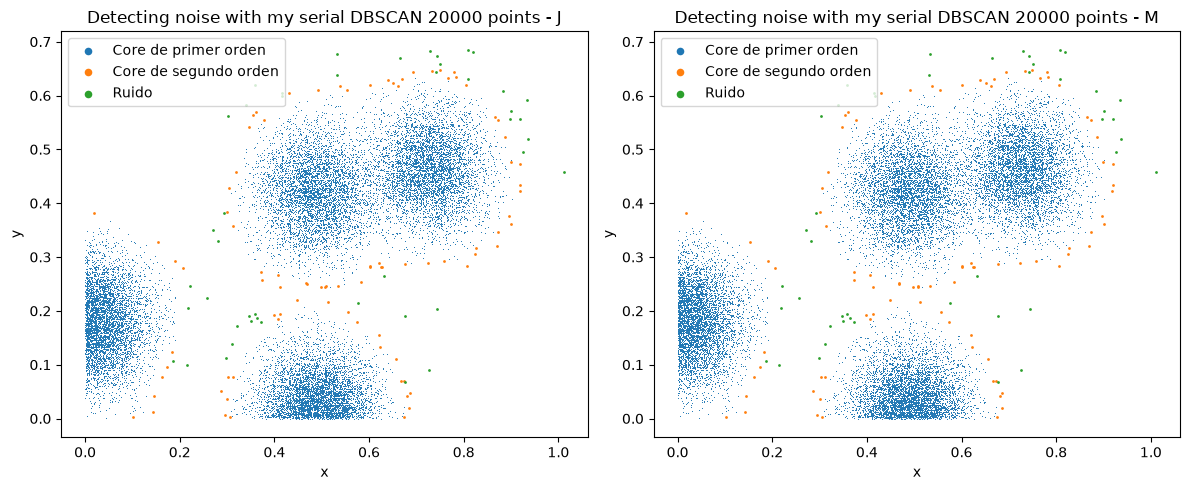

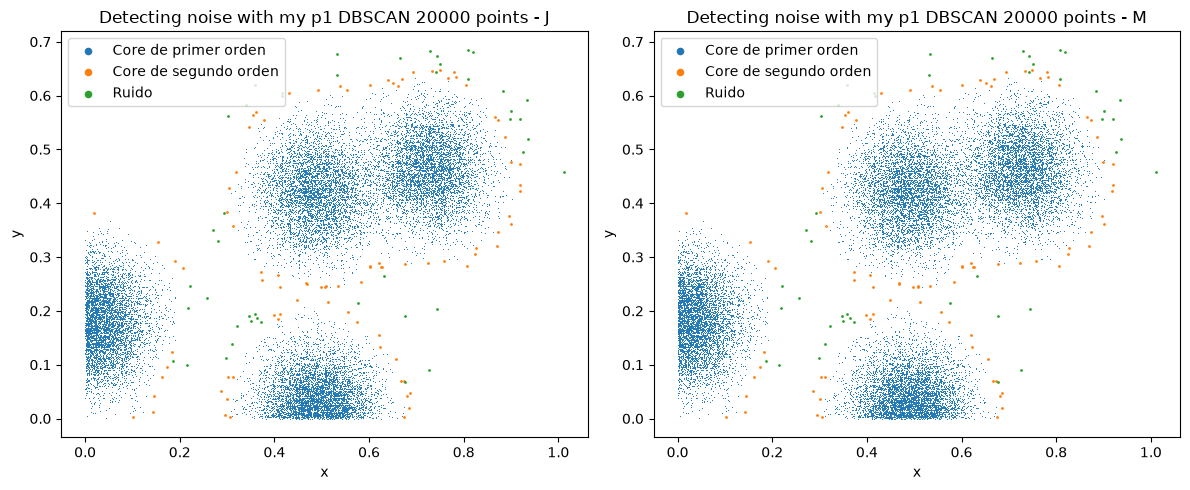

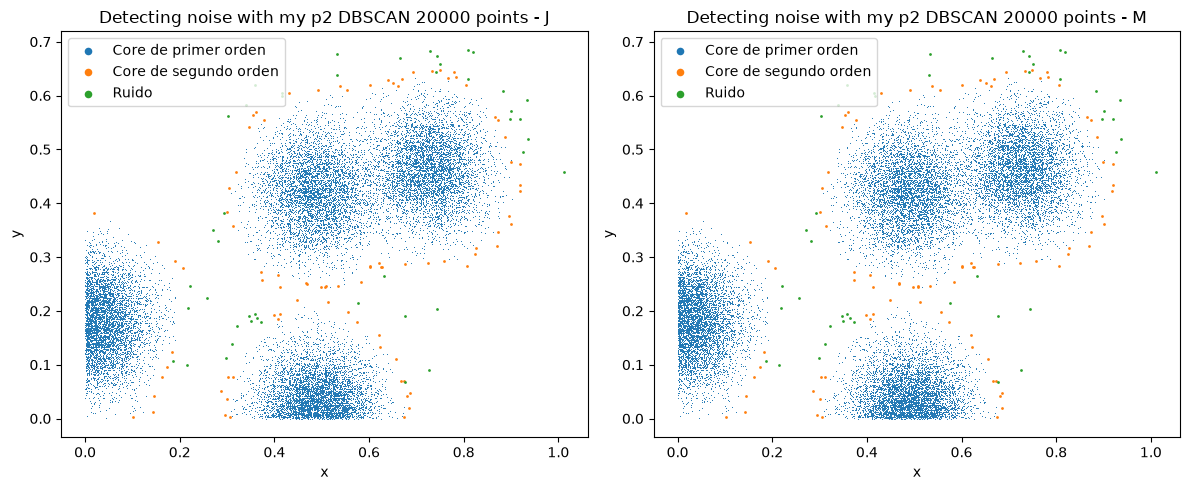

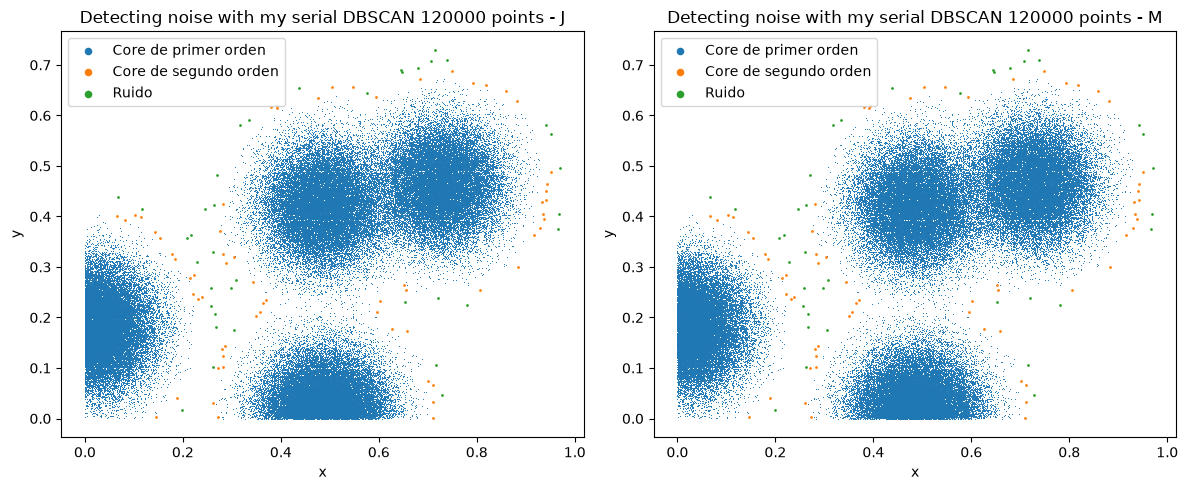

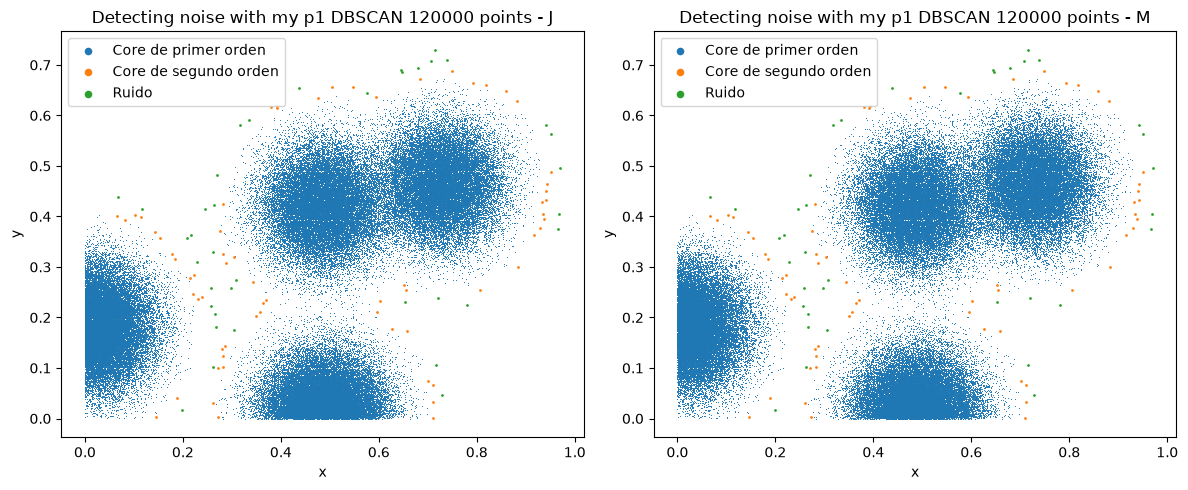

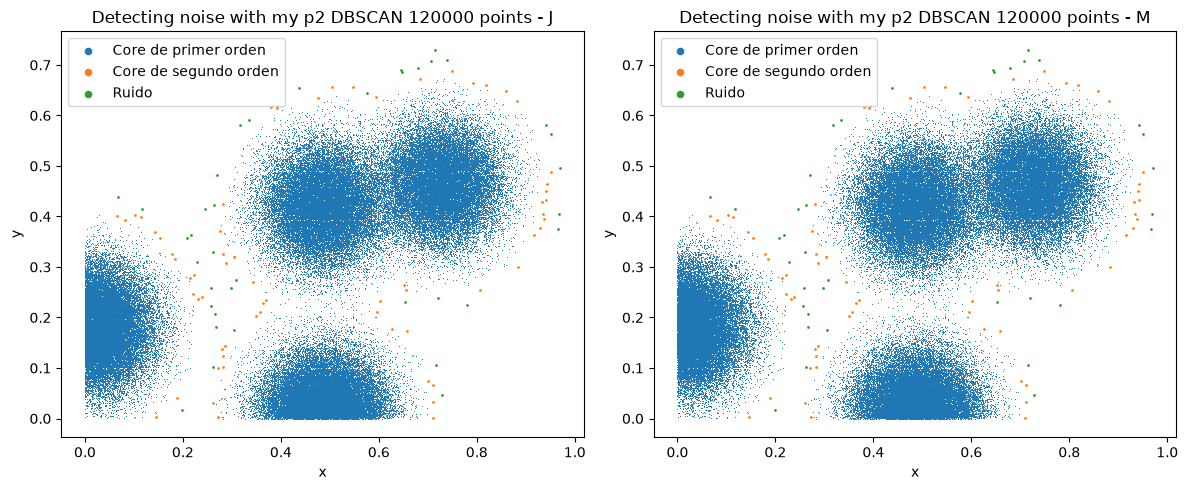

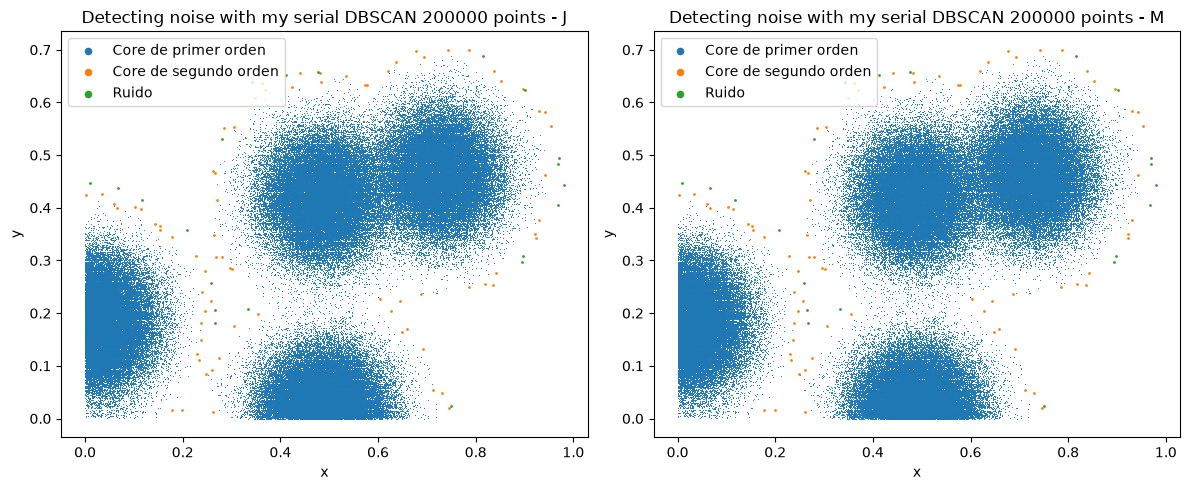

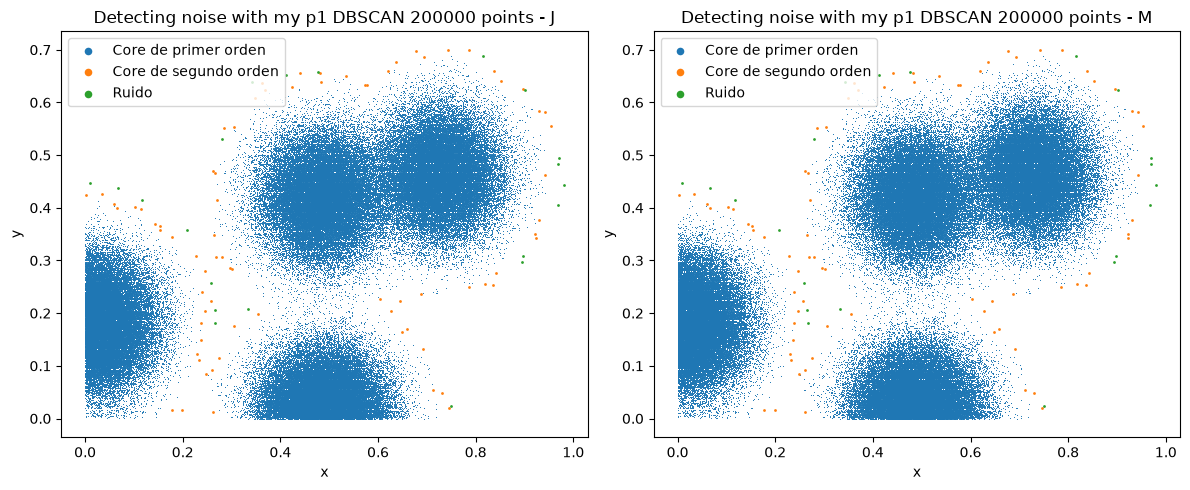

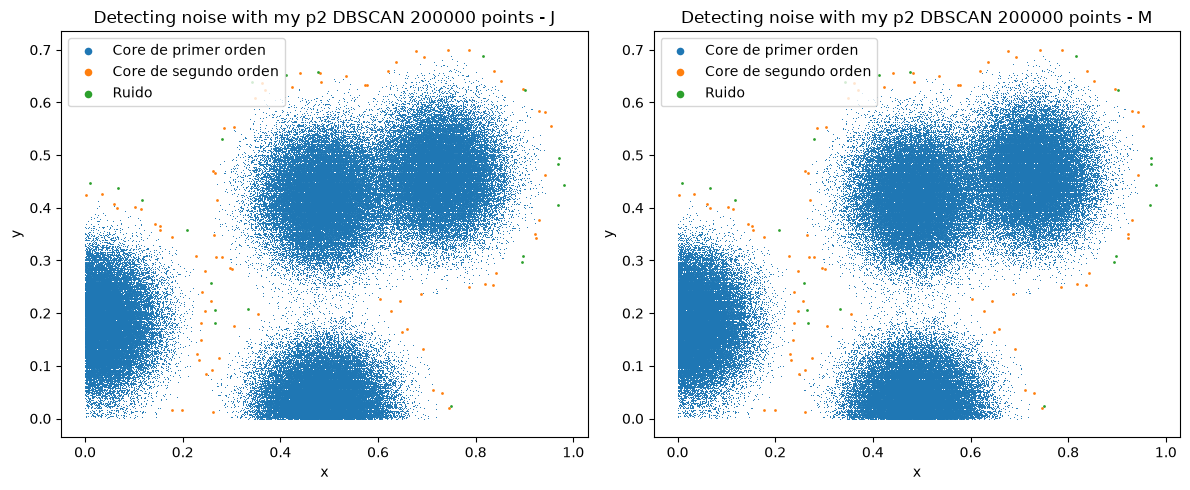

In [2]:
# Visualizacion de la clasificacion de cada computadora por separado, J y M, y de las dos juntas, U
import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("graficas", exist_ok=True)

equipos = ["J", "M"]

# Indicate the number of points
for n_points in [20000, 120000, 200000]:
    for version in ["serial", "p1", "p2"]:
        # Una grafica solo de J, otra solo de M y otra con las dos, J a la izquierda y M a la derecha
        for vista in ["J", "M", "U"]:
            if vista == "U":
                plt.figure(figsize=(12, 5))
            else:
                plt.figure(figsize=(6, 5))

            for i in range(2):
                equipo = equipos[i]
                if vista == "U" or vista == equipo:
                    if vista == "U":
                        plt.subplot(1, 2, i + 1)

                    # loading results from c++ program into a numpy array
                    if version == "serial":
                        archivo = "datos/"+str(n_points)+"_results_"+equipo+".csv"
                    else:
                        archivo = "datos/"+str(n_points)+"_results_"+version+"_"+equipo+".csv"

                    # Si esa computadora no tiene el archivo se deja su lado vacio
                    if not os.path.exists(archivo):
                        plt.title("Sin resultados de " + version + " - " + equipo)
                        plt.axis("off")
                    else:
                        result = np.loadtxt(archivo, delimiter=",")

                        # plotting noise
                        plt.title("Detecting noise with my " + version + " DBSCAN " + str(n_points) + " points - " + equipo)
                        corePrimero = result[result.T[2] == 1]
                        coreSegundo = result[result.T[2] == 2]
                        ruido = result[result.T[2] == 0]
                        plt.scatter(corePrimero.T[0], corePrimero.T[1], s=0.5, linewidths=0, label="Core de primer orden")
                        plt.scatter(coreSegundo.T[0], coreSegundo.T[1], s=4, linewidths=0, label="Core de segundo orden")
                        plt.scatter(ruido.T[0], ruido.T[1], s=4, linewidths=0, label="Ruido")
                        plt.xlabel("x")
                        plt.ylabel("y")
                        # Los puntos de la leyenda se dibujan del mismo tamano para que se vea bien el color
                        leyenda = plt.legend()
                        for marca in leyenda.legend_handles:
                            marca.set_sizes([30])

            plt.tight_layout()
            plt.savefig("graficas/clasificacion_" + version + "_" + str(n_points) + "_" + vista + ".png")
            # Solo se muestra la grafica con las dos computadoras, las otras solo se guardan
            if vista == "U":
                plt.show()
            else:
                plt.close()

In [ ]:
# Comparacion del serial contra el DBSCAN de sklearn con los mismos parametros
# Para sklearn el ruido es la etiqueta -1 y para nuestro programa es la etiqueta 0
from sklearn.cluster import DBSCAN

# sklearn guarda en memoria los vecinos de cada punto, con 200000 puntos ocupa alrededor de 7 GB
for n_points in [20000, 40000, 80000, 120000, 140000, 160000, 180000, 200000]:
    points = np.loadtxt("datos/"+str(n_points)+"_data.csv", delimiter=",")

    # clustering and detecting noise with dbscan
    clusters = DBSCAN(eps=0.03, min_samples=10).fit_predict(points)

    result = np.loadtxt("datos/"+str(n_points)+"_results_J.csv", delimiter=",")
    ruidoSklearn = clusters == -1
    ruidoSerial = result.T[2] == 0
    diferencias = np.sum(ruidoSklearn != ruidoSerial)
    print(n_points, "puntos, ruido sklearn", np.sum(ruidoSklearn), ", ruido serial", np.sum(ruidoSerial), ", diferencias", diferencias)

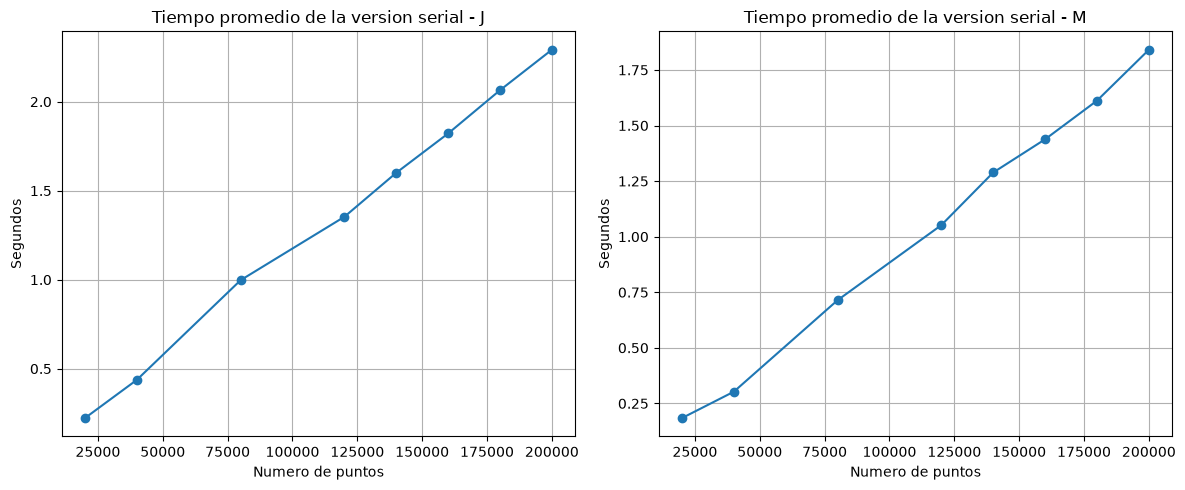

In [3]:
# Tiempo promedio de la version serial contra el numero de puntos
# Una grafica solo de J, otra solo de M y otra con las dos, J a la izquierda y M a la derecha
for vista in ["J", "M", "U"]:
    if vista == "U":
        plt.figure(figsize=(12, 5))
    else:
        plt.figure(figsize=(6, 5))

    for lado in range(2):
        equipo = equipos[lado]
        if vista == "U" or vista == equipo:
            if vista == "U":
                plt.subplot(1, 2, lado + 1)

            datosSerial = np.loadtxt("datos/tiempos_serial_"+equipo+".csv", delimiter=",", skiprows=1)
            tamanos = datosSerial.T[0]
            promedios = datosSerial.T[1]

            plt.plot(tamanos, promedios, marker="o")
            plt.title("Tiempo promedio de la version serial - " + equipo)
            plt.xlabel("Numero de puntos")
            plt.ylabel("Segundos")
            plt.grid(True)
    plt.tight_layout()
    plt.savefig("graficas/tiempo_serial_" + vista + ".png")
    # Solo se muestra la grafica con las dos computadoras, las otras solo se guardan
    if vista == "U":
        plt.show()
    else:
        plt.close()

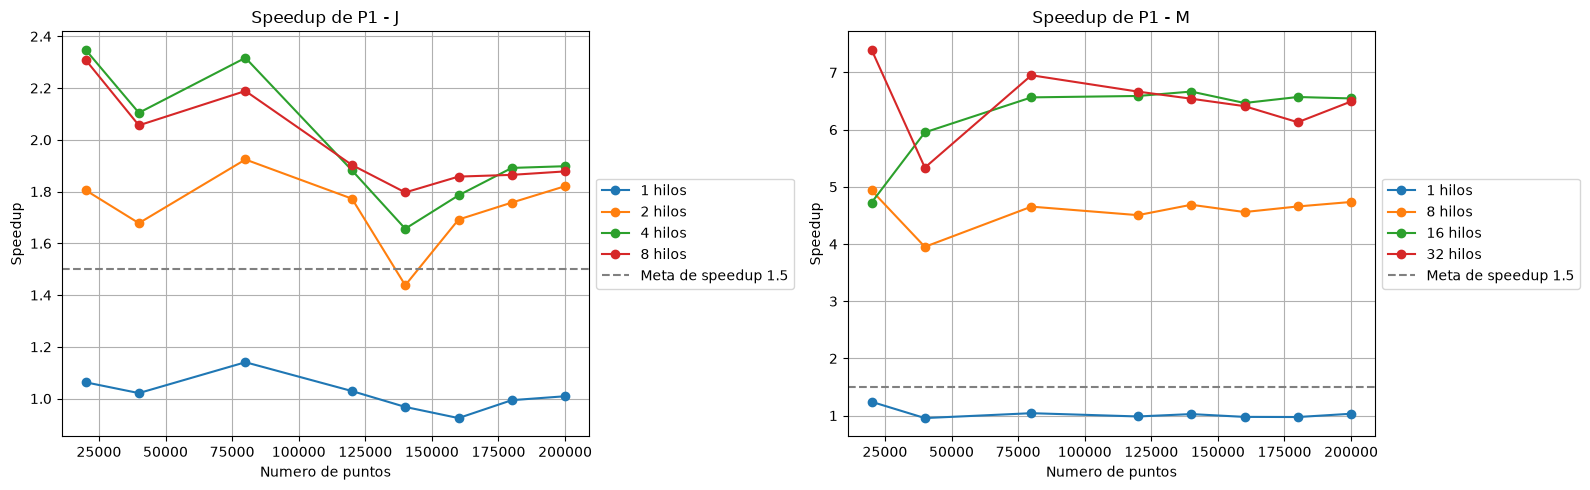

In [4]:
# Speedup de P1 con distinto numero de hilos
# Speedup es el tiempo serial entre el tiempo paralelo
# Una grafica solo de J, otra solo de M y otra con las dos, J a la izquierda y M a la derecha
for vista in ["J", "M", "U"]:
    if vista == "U":
        plt.figure(figsize=(16, 5))
    else:
        plt.figure(figsize=(8, 5))

    for lado in range(2):
        equipo = equipos[lado]
        if vista == "U" or vista == equipo:
            if vista == "U":
                plt.subplot(1, 2, lado + 1)

            datosSerial = np.loadtxt("datos/tiempos_serial_"+equipo+".csv", delimiter=",", skiprows=1)
            tamanos = datosSerial.T[0]
            promedios = datosSerial.T[1]
            datosP1 = np.loadtxt("datos/tiempos_p1_"+equipo+".csv", delimiter=",", skiprows=1)

            # Los hilos los decide el programa de C++ con los cores virtuales de la computadora
            # Se toman de los renglones del primer tamano
            hilos = []
            for fila in datosP1:
                if fila[0] == tamanos[0]:
                    hilos.append(int(fila[1]))

            for h in hilos:
                speedups = []
                for i in range(len(tamanos)):
                    for fila in datosP1:
                        if fila[0] == tamanos[i] and fila[1] == h:
                            speedups.append(promedios[i] / fila[3])
                plt.plot(tamanos, speedups, marker="o", label=str(h) + " hilos")
            plt.axhline(1.5, color="gray", linestyle="dashed", label="Meta de speedup 1.5")
            plt.title("Speedup de P1 - " + equipo)
            plt.xlabel("Numero de puntos")
            plt.ylabel("Speedup")
            plt.grid(True)
            plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    plt.savefig("graficas/speedup_p1_" + vista + ".png")
    # Solo se muestra la grafica con las dos computadoras, las otras solo se guardan
    if vista == "U":
        plt.show()
    else:
        plt.close()

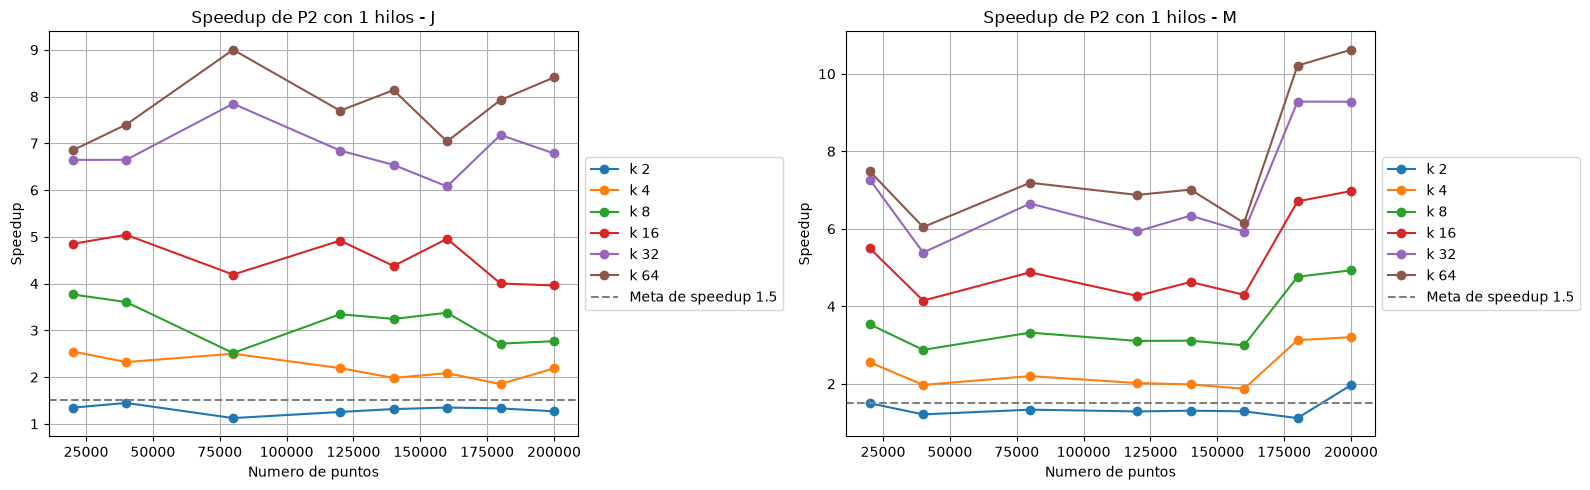

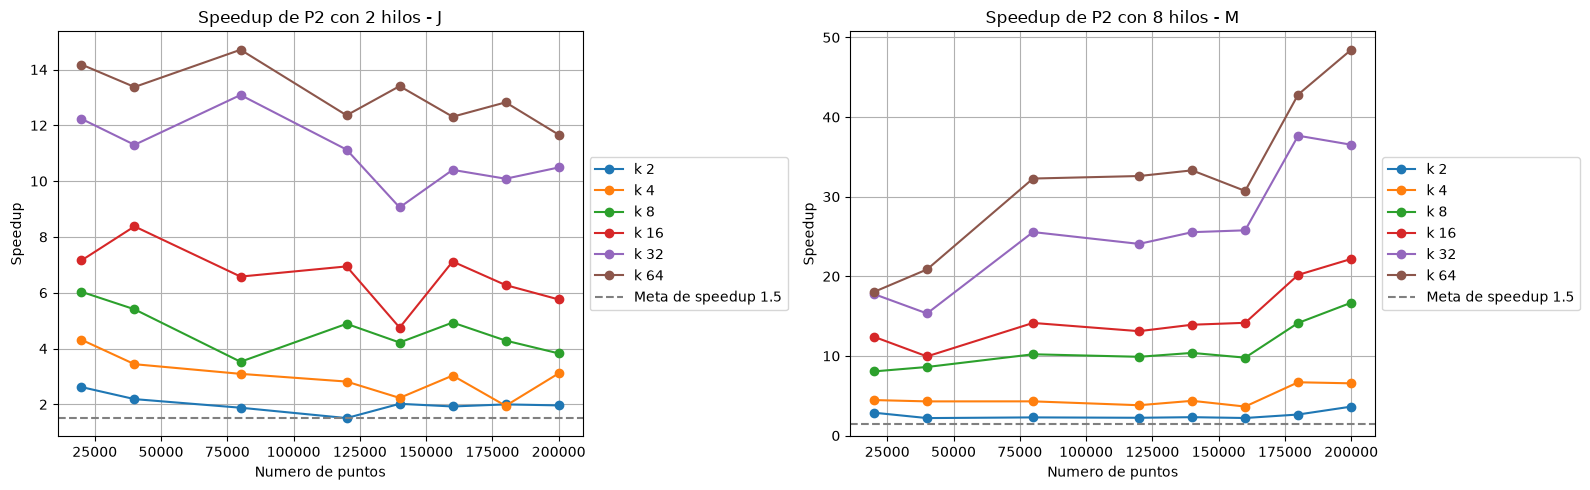

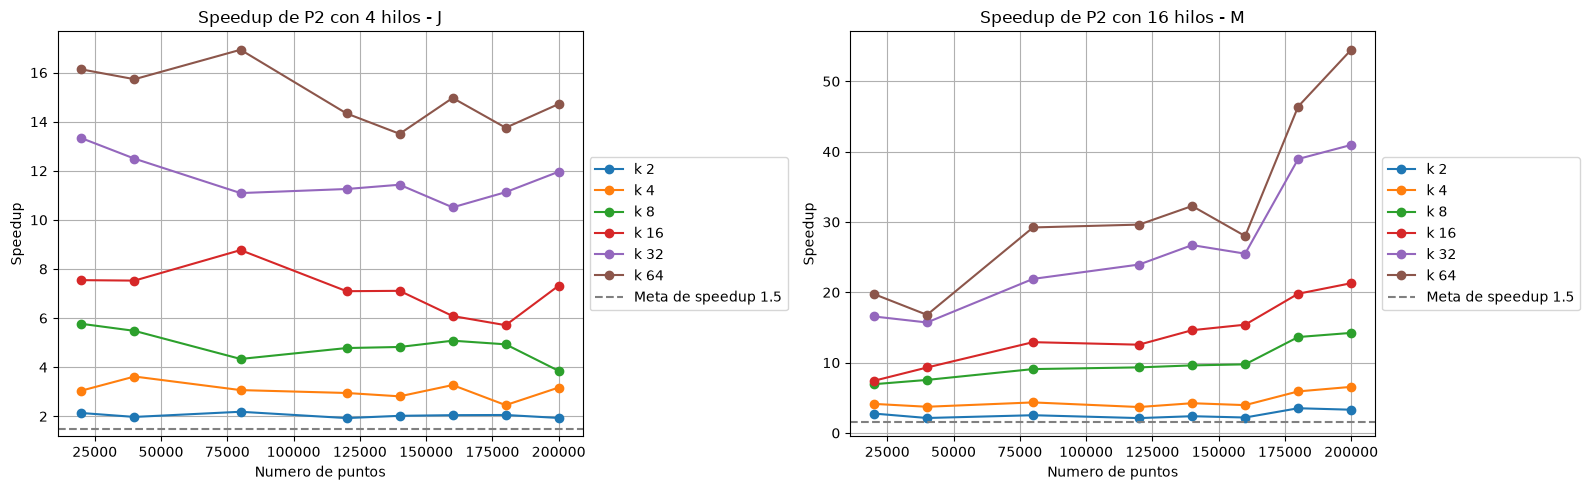

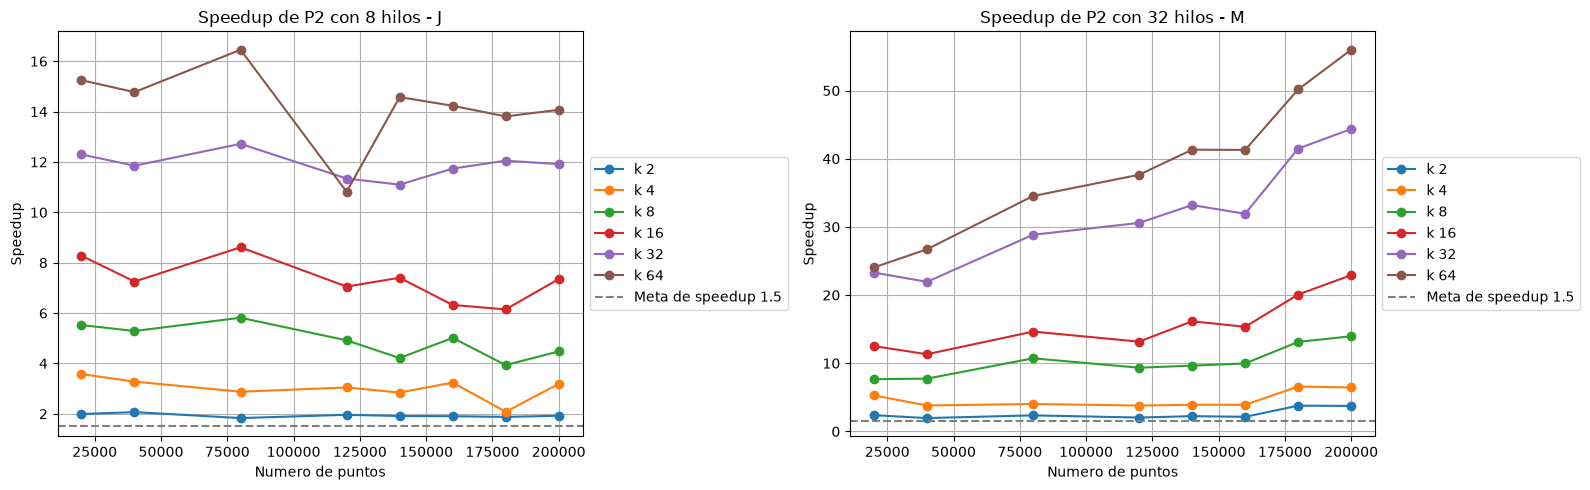

In [5]:
# Speedup de P2 con distinto numero de hilos y distintos valores de k
# Cada figura usa el mismo lugar de la lista de hilos, que es 1, la mitad de los cores, los cores y el doble
# Una grafica solo de J, otra solo de M y otra con las dos, J a la izquierda y M a la derecha
nombres = ["un_hilo", "mitad_cores", "cores", "doble_cores"]
for posicion in range(4):
    for vista in ["J", "M", "U"]:
        if vista == "U":
            plt.figure(figsize=(16, 5))
        else:
            plt.figure(figsize=(8, 5))

        for lado in range(2):
            equipo = equipos[lado]
            if vista == "U" or vista == equipo:
                if vista == "U":
                    plt.subplot(1, 2, lado + 1)

                datosSerial = np.loadtxt("datos/tiempos_serial_"+equipo+".csv", delimiter=",", skiprows=1)
                tamanos = datosSerial.T[0]
                promedios = datosSerial.T[1]
                datosP1 = np.loadtxt("datos/tiempos_p1_"+equipo+".csv", delimiter=",", skiprows=1)
                datosP2 = np.loadtxt("datos/tiempos_p2_"+equipo+".csv", delimiter=",", skiprows=1)

                hilos = []
                for fila in datosP1:
                    if fila[0] == tamanos[0]:
                        hilos.append(int(fila[1]))
                h = hilos[posicion]

                for k in [2, 4, 8, 16, 32, 64]:
                    speedups = []
                    for i in range(len(tamanos)):
                        for fila in datosP2:
                            if fila[0] == tamanos[i] and fila[1] == h and fila[2] == k:
                                speedups.append(promedios[i] / fila[3])
                    plt.plot(tamanos, speedups, marker="o", label="k " + str(k))
                plt.axhline(1.5, color="gray", linestyle="dashed", label="Meta de speedup 1.5")
                plt.title("Speedup de P2 con " + str(h) + " hilos - " + equipo)
                plt.xlabel("Numero de puntos")
                plt.ylabel("Speedup")
                plt.grid(True)
                plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
        plt.tight_layout()
        plt.savefig("graficas/speedup_p2_" + nombres[posicion] + "_" + vista + ".png")
        # Solo se muestra la grafica con las dos computadoras, las otras solo se guardan
        if vista == "U":
            plt.show()
        else:
            plt.close()

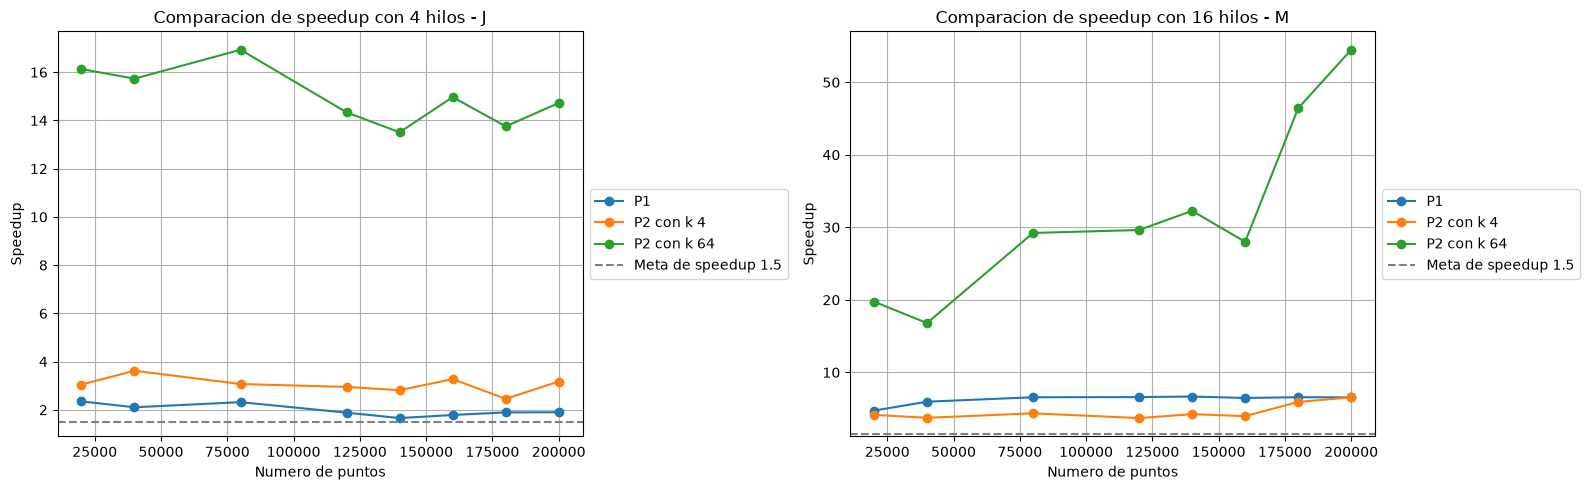

In [6]:
# Comparacion de P1 y P2 con tantos hilos como cores virtuales, P2 con k igual a 4 y a 64
# Una grafica solo de J, otra solo de M y otra con las dos, J a la izquierda y M a la derecha
for vista in ["J", "M", "U"]:
    if vista == "U":
        plt.figure(figsize=(16, 5))
    else:
        plt.figure(figsize=(8, 5))

    for lado in range(2):
        equipo = equipos[lado]
        if vista == "U" or vista == equipo:
            if vista == "U":
                plt.subplot(1, 2, lado + 1)

            datosSerial = np.loadtxt("datos/tiempos_serial_"+equipo+".csv", delimiter=",", skiprows=1)
            tamanos = datosSerial.T[0]
            promedios = datosSerial.T[1]
            datosP1 = np.loadtxt("datos/tiempos_p1_"+equipo+".csv", delimiter=",", skiprows=1)
            datosP2 = np.loadtxt("datos/tiempos_p2_"+equipo+".csv", delimiter=",", skiprows=1)

            hilos = []
            for fila in datosP1:
                if fila[0] == tamanos[0]:
                    hilos.append(int(fila[1]))
            cores = hilos[2]

            speedupsP1 = []
            speedupsP2k4 = []
            speedupsP2k64 = []
            for i in range(len(tamanos)):
                for fila in datosP1:
                    if fila[0] == tamanos[i] and fila[1] == cores:
                        speedupsP1.append(promedios[i] / fila[3])
                for fila in datosP2:
                    if fila[0] == tamanos[i] and fila[1] == cores and fila[2] == 4:
                        speedupsP2k4.append(promedios[i] / fila[3])
                    if fila[0] == tamanos[i] and fila[1] == cores and fila[2] == 64:
                        speedupsP2k64.append(promedios[i] / fila[3])

            plt.plot(tamanos, speedupsP1, marker="o", label="P1")
            plt.plot(tamanos, speedupsP2k4, marker="o", label="P2 con k 4")
            plt.plot(tamanos, speedupsP2k64, marker="o", label="P2 con k 64")
            plt.axhline(1.5, color="gray", linestyle="dashed", label="Meta de speedup 1.5")
            plt.title("Comparacion de speedup con " + str(cores) + " hilos - " + equipo)
            plt.xlabel("Numero de puntos")
            plt.ylabel("Speedup")
            plt.grid(True)
            plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    plt.savefig("graficas/comparacion_" + vista + ".png")
    # Solo se muestra la grafica con las dos computadoras, las otras solo se guardan
    if vista == "U":
        plt.show()
    else:
        plt.close()